### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Getting dataset

In [2]:
df=pd.read_csv("dataset/olist_customers_dataset.csv")
df.head(2)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


### Inferece
1) we have customer_id to assign unique customer_id for customer to each order, not to identify individual customer/user.
2) customer_unique_id is assigned to each used to identtify each user individually.
3) we have cutomer_zip_code_prefix, customer_city, customer_state to get customer address.

In [4]:
df.shape

(99441, 5)

In [5]:
df.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

### Insights 

In [7]:
# unique Customer/ Total Customers
print(df['customer_unique_id'].nunique())

96096


In [37]:
x1=df.groupby('customer_city')['customer_unique_id'].nunique()
x1=x1.reset_index().sort_values(by='customer_unique_id',ascending=False)
x1.columns=['Customer city','Customers Count']
x1

,Customer city,Customers Count
3597,sao paulo,14984
3155,rio de janeiro,6620
453,belo horizonte,2672
558,brasilia,2069
1143,curitiba,1465
...,...,...
1571,ibertioga,1
1575,ibiajara,1
1578,ibiara,1
1583,ibicuitinga,1


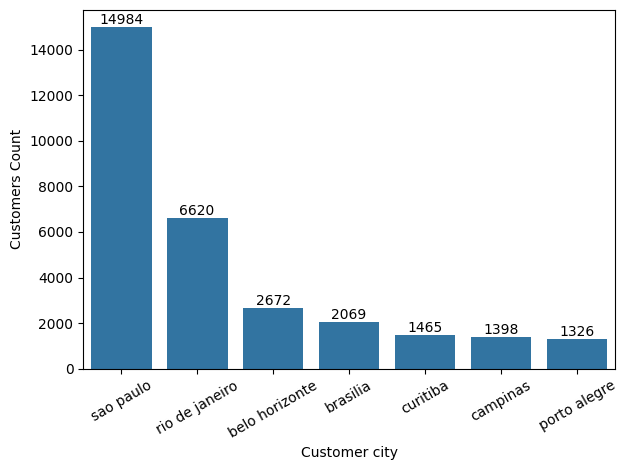

In [64]:
### top 7 city by customer
p1=x1.iloc[:7,:]
ax=sns.barplot(p1,x='Customer city',y='Customers Count')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [50]:
###  Orders per city
x2=df.groupby('customer_city')['customer_id'].nunique().reset_index().sort_values(by='Orders',ascending=False)
x2.columns=['Customer city','Orders']
x2

,Customer city,Orders
3597,sao paulo,15540
3155,rio de janeiro,6882
453,belo horizonte,2773
558,brasilia,2131
1143,curitiba,1521
...,...,...
1578,ibiara,1
3164,rio espera,1
3163,rio dos indios,1
3162,rio dos cedros,1


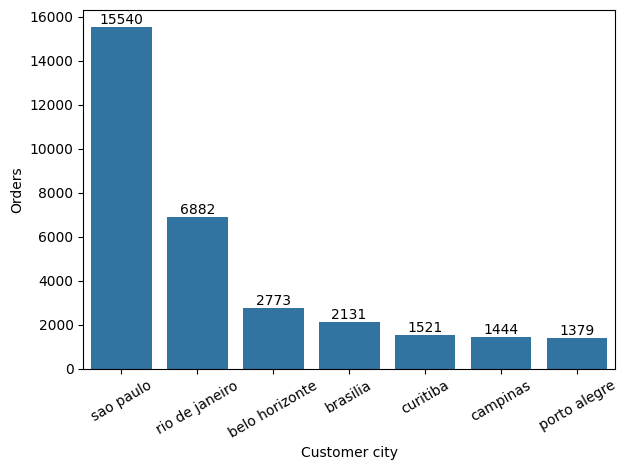

In [51]:
### top 7 city by orders
p2=x2.iloc[:7,:]
ax=sns.barplot(p2,x='Customer city',y='Orders')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [52]:
x3=df.groupby('customer_state')['customer_unique_id'].nunique()
x3=x3.reset_index().sort_values(by='customer_unique_id',ascending=False)
x3.columns=['Customer state','Customers']
x3


,Customer state,Customers
25,SP,40302
18,RJ,12384
10,MG,11259
22,RS,5277
17,PR,4882
23,SC,3534
4,BA,3277
6,DF,2075
7,ES,1964
8,GO,1952


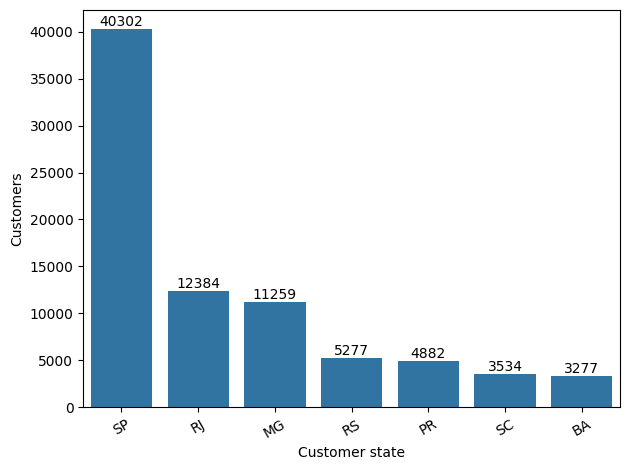

In [61]:
### top 7 city by orders
p3=x3.iloc[:7,:]
ax=sns.barplot(p3,x='Customer state',y='Customers')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [56]:
x4=df.groupby('customer_state')['customer_id'].nunique()
x4=x4.reset_index().sort_values(by='customer_id',ascending=False)
x4.columns=['Customer state','Orders']
x4

,Customer state,Orders
25,SP,41746
18,RJ,12852
10,MG,11635
22,RS,5466
17,PR,5045
23,SC,3637
4,BA,3380
6,DF,2140
7,ES,2033
8,GO,2020


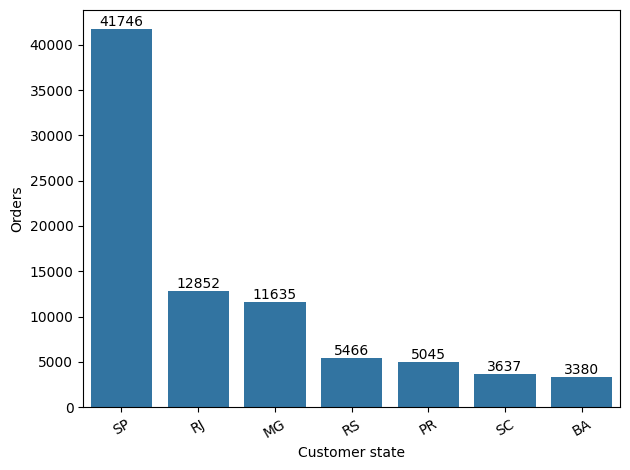

In [57]:
### top 7 state by orders
p4=x4.iloc[:7,:]
ax=sns.barplot(p4,x='Customer state',y='Orders')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

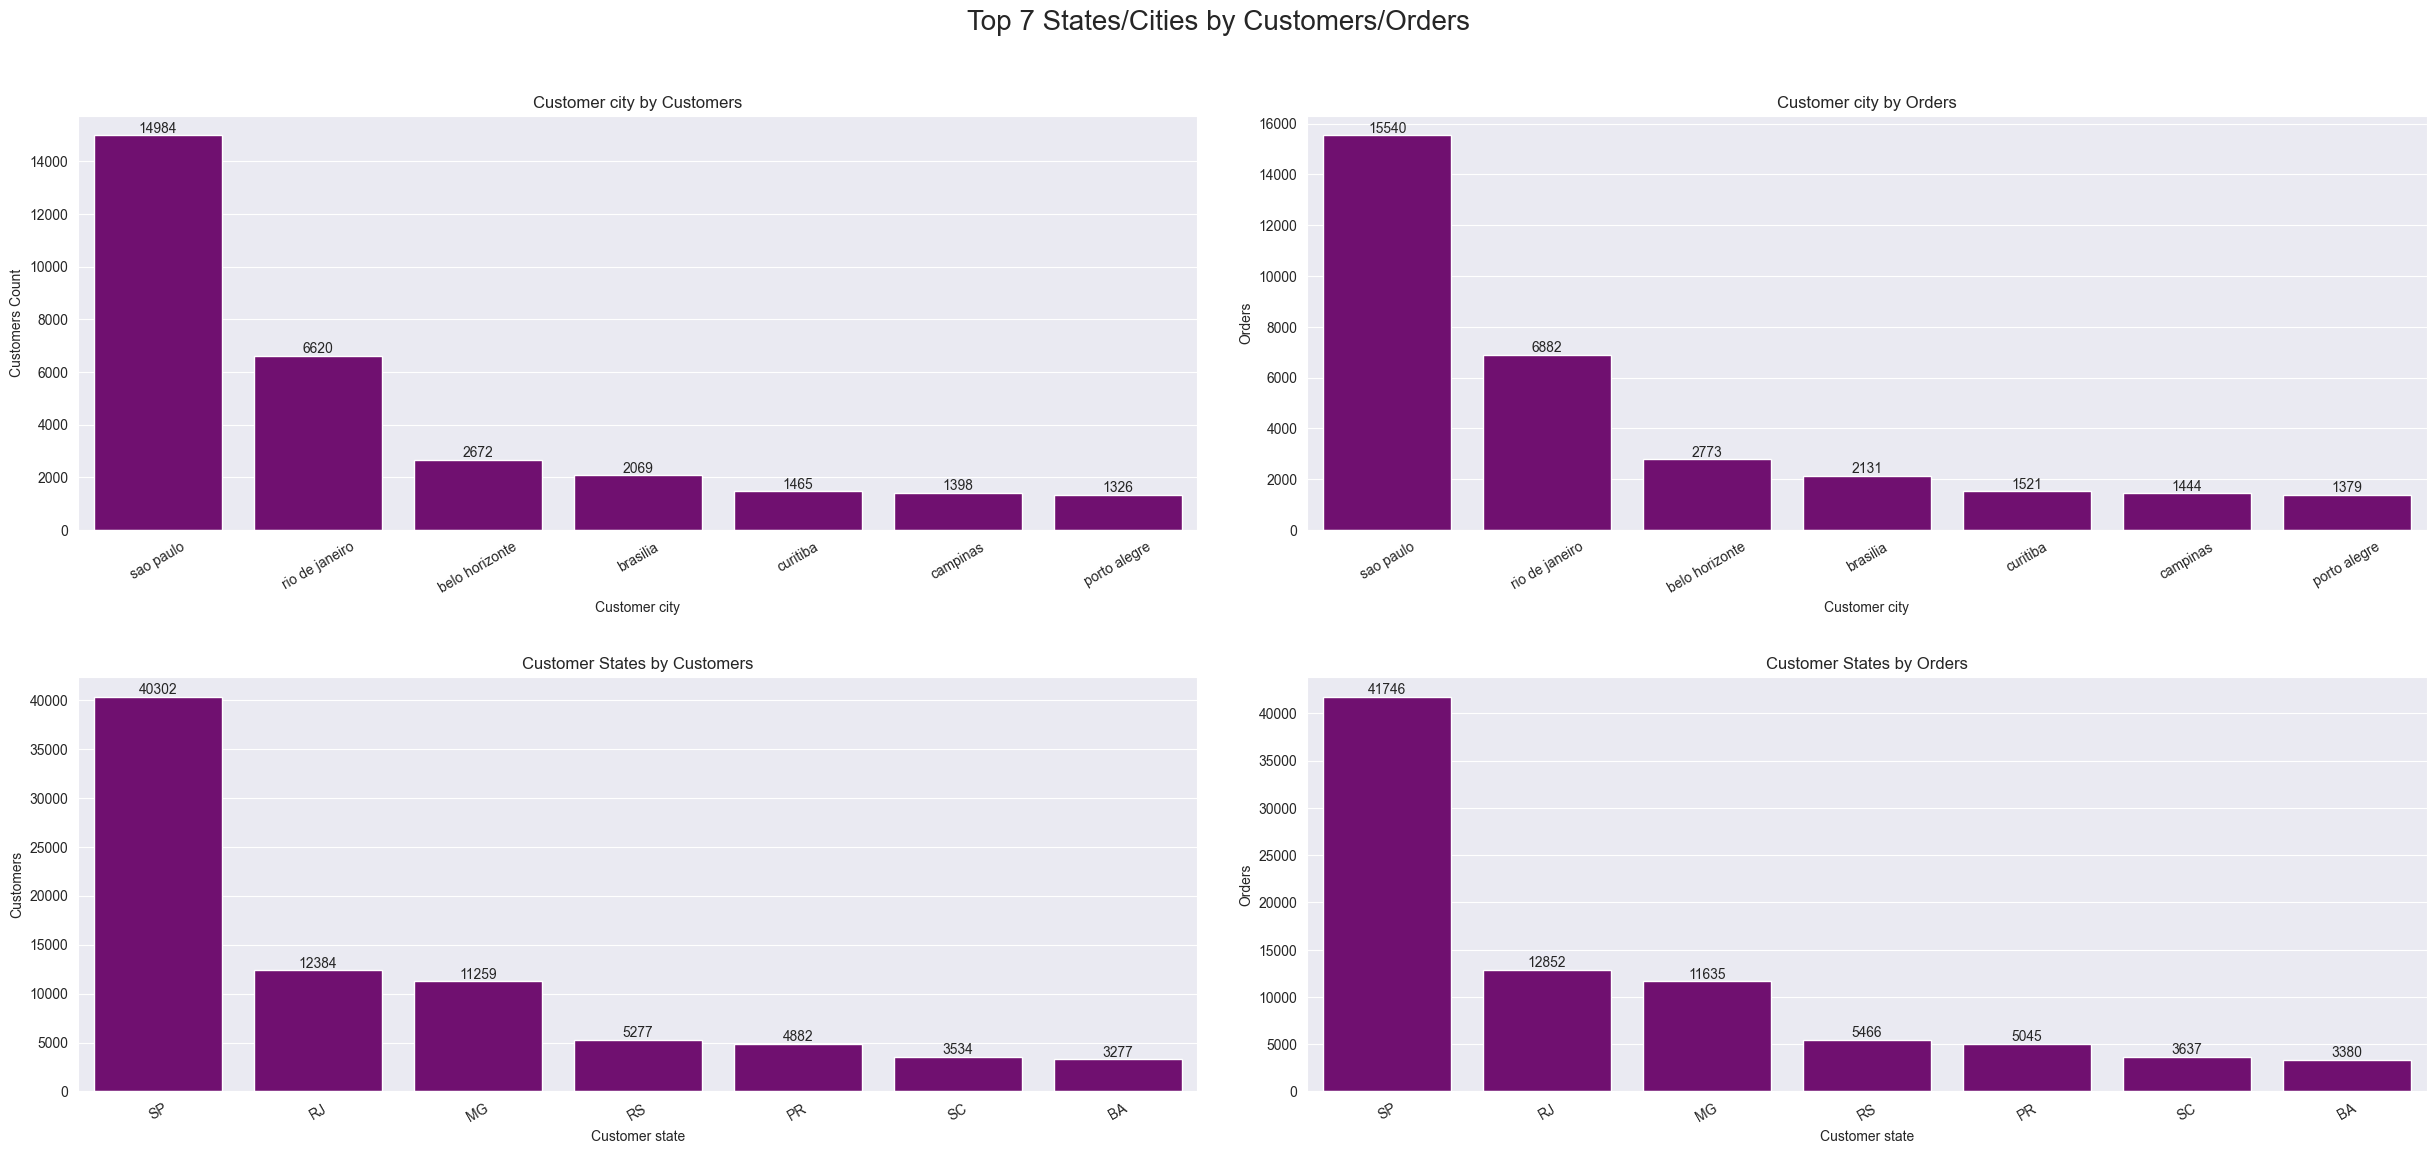

In [89]:
sns.set_style('darkgrid')

fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(25,12))

ax1=sns.barplot(p1,x='Customer city',y='Customers Count',ax=axes[0,0], color="purple")
ax1.bar_label(ax1.containers[0])
ax1.set_title("Customer city by Customers")
ax1.tick_params(axis='x', rotation=30)

ax2=sns.barplot(p2,x='Customer city',y='Orders',ax=axes[0,1], color="purple")
ax2.bar_label(ax2.containers[0])
ax2.set_title("Customer city by Orders")
ax2.tick_params(axis='x', rotation=30)

ax3=sns.barplot(p3,x='Customer state',y='Customers',ax=axes[1,0], color="purple")
ax3.bar_label(ax3.containers[0])
ax3.set_title("Customer States by Customers")
ax3.tick_params(axis='x', rotation=30)

ax4=sns.barplot(p4,x='Customer state',y='Orders',ax=axes[1,1], color="purple")
ax4.bar_label(ax4.containers[0])
ax4.set_title('Customer States by Orders')
ax4.tick_params(axis='x', rotation=30)

fig.suptitle("Top 7 States/Cities by Customers/Orders",fontsize=20)

plt.tight_layout(pad=3)
plt.savefig('Customer_insights.png',dpi=500,bbox_inches="tight")
plt.show()